# Rap en bobine — détection des figures du cinéma avec Mistral Small 3.1 24B

**Objectif.** Pour chaque chanson de rap du corpus, relever **au fil de la lecture** toutes les
figures du cinéma présentes dans les paroles : films, séries, personnages, acteur·rices,
réalisateur·rices, répliques ou scènes. Chaque occurrence donne une détection
`{justification, extrait, figure, oeuvre}`, répétitions comprises (refrains) ; une dizaine de détections
par chanson n'a rien d'étonnant.

**Données.** `Rap/corpus_clean.csv` (paroles nettoyées). Le fichier des annotations Genius
n'étant pas encore disponible, le modèle travaille **uniquement sur le texte de la chanson**
(contrairement au script `detect_cinema_mistral.py`, qui exploitait fragment + annotation).

**Modèle.** `mistralai/Mistral-Small-3.1-24B-Instruct-2503`, servi en local par vLLM
(API compatible OpenAI), **température 0** et sortie contrainte par un schéma JSON strict
pour des résultats déterministes et toujours parseables.

**Nouveau run : 2021 à 2024 inclus.** Après le pilote de 2 000 chansons, sélectionner
toutes les chansons éligibles de cette période stricte, puis lancer manuellement
l'annotation (section 5). Le corpus fournit uniquement l'année : aucun filtrage au jour près
n'est possible. Années absentes, non entières ou futures exclues ; paroles non vides et ≥ 10 mots.
Les sorties portent le suffixe `<année_début>_<année_fin>_all`, distinct des anciens pilotes.
Pour un test aléatoire sur cette période, régler `N_SAMPLE` sur un entier positif.

**Sorties** (convention `data/` du dépôt) :
- `data/results/cinema_mistral24b_detections_<suffixe>.csv` — une ligne par détection, dans l'ordre de lecture ;
- `data/results/cinema_mistral24b_chansons_<suffixe>.csv` — une ligne par chanson, même sans détection (statut, durée) ;
- `data/performance/cinema_mistral24b_<suffixe>_report.csv` — métriques du run et bornes temporelles ;
- `images/cinema_*_<suffixe>.png` — graphiques individuels : statistiques descriptives et
  nuages de mots par figure (palette hip-hop du dépôt).


## 1. Prérequis : lancer le serveur vLLM

Le kernel du notebook nécessite `pandas`, `requests`, `tqdm`, `matplotlib` et `wordcloud`.
Exécuter les cellules dans l'ordre depuis un kernel redémarré pour ce nouveau run.
L'annotation ne commence qu'à la section 5 ; les sections précédentes préparent la sélection.

Le serveur doit tourner **avant** les cellules suivantes ; le notebook le vérifie mais ne le
démarre pas. Il tourne dans l'env `vllm312`, avec le `libstdc++` de l'env conda `vllm_mistral`
préchargé pour éviter l'erreur `GLIBCXX`. Le modèle occupe environ 48 Go sur le GPU 1 (H100)
(vérifier avec `nvidia-smi` et adapter `CUDA_VISIBLE_DEVICES`). Démarrage : environ 1 min 30.

```bash
tmux new -d -s agent-cinema-vllm "CUDA_VISIBLE_DEVICES=1 \
LD_PRELOAD=/home/cbenavent/miniconda3/envs/vllm_mistral/lib/libstdc++.so.6 \
HF_HUB_OFFLINE=1 \
/home/cbenavent/envs/vllm312/bin/python -m vllm.entrypoints.openai.api_server \
  --model mistralai/Mistral-Small-3.1-24B-Instruct-2503 \
  --served-model-name mistralai/Mistral-Small-3.1-24B-Instruct-2503 \
  --host 127.0.0.1 --port 8014 --api-key \$(cat ~/.vllm_key) \
  --dtype bfloat16 --gpu-memory-utilization 0.85 --max-model-len 16384 \
  --no-enable-log-requests"
```

Vérification : `curl -fsS -H "Authorization: Bearer $(cat ~/.vllm_key)" http://127.0.0.1:8014/v1/models`.
Arrêt en fin de session : `tmux kill-session -t agent-cinema-vllm` (puis contrôler `nvidia-smi`).


In [11]:
from datetime import date

# ====================== PARAMÈTRES À RÉGLER ======================
# --- Échantillon ---
# Un entier = échantillon de la période ; None = toutes les chansons de la période.
N_SAMPLE = None
YEAR_MIN = 2021
YEAR_MAX = 2024
SEED = 42
# --- Inférence ---
MAX_CHARS = 12000    # troncature des paroles envoyées au modèle (~3 000 tokens)
MAX_TOKENS = 4096    # budget de sortie (détections avec justification)
                     # 12 000 chars de paroles (~4 300 tokens) + consigne + 4 096 tokens < contexte 16 384
                     # nécessite --max-model-len 16384 côté serveur (cf. section 1)
MAX_DETECTIONS = 60  # plafond du schéma (maxItems) : coupe proprement les refrains très répétitifs
TIMEOUT = 300        # secondes par requête
MAX_ESSAIS = 2       # tentatives par chanson en cas d'erreur transitoire
MAX_WORKERS = 24     # une chanson par requête ; batching dynamique côté vLLM
# ==================================================================

from concurrent.futures import ThreadPoolExecutor, as_completed
from pathlib import Path
import json
import time

import pandas as pd
import requests
from tqdm.auto import tqdm

PROJECT_DIR = Path('/home/cbenavent/test/Rap/Rap_en_bobine')
CORPUS_PATH = PROJECT_DIR.parent / 'corpus_clean.csv'
RESULTS_DIR = PROJECT_DIR / 'data' / 'results'
PERF_DIR = PROJECT_DIR / 'data' / 'performance'
IMAGES_DIR = PROJECT_DIR / 'images'
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
PERF_DIR.mkdir(parents=True, exist_ok=True)
IMAGES_DIR.mkdir(parents=True, exist_ok=True)

API_URL = 'http://127.0.0.1:8014/v1'
MODEL = 'mistralai/Mistral-Small-3.1-24B-Instruct-2503'
cle_path = Path.home() / '.vllm_key'
API_KEY = cle_path.read_text().strip() if cle_path.is_file() else 'EMPTY'
HEADERS = {'Authorization': f'Bearer {API_KEY}'}

if N_SAMPLE is not None and (type(N_SAMPLE) is not int or N_SAMPLE <= 0):
    raise ValueError('N_SAMPLE doit être un entier positif, ou None pour le corpus complet.')
if type(YEAR_MIN) is not int or type(YEAR_MAX) is not int or not 1 <= YEAR_MIN <= YEAR_MAX <= date.today().year:
    raise ValueError('Bornes temporelles invalides : années entières, début ≤ fin ≤ année courante.')
if min(MAX_CHARS, MAX_TOKENS, TIMEOUT, MAX_ESSAIS, MAX_WORKERS) <= 0:
    raise ValueError('MAX_CHARS, MAX_TOKENS, TIMEOUT, MAX_ESSAIS et MAX_WORKERS doivent être positifs.')

print('Corpus :', CORPUS_PATH)
print('Modèle :', MODEL, '| endpoint :', API_URL)
print(f'Période : {YEAR_MIN}–{YEAR_MAX} inclus')
print('Échantillon :', N_SAMPLE if N_SAMPLE is not None else 'toute la période',
      '| graine :', SEED, '| workers :', MAX_WORKERS)


Corpus : /home/cbenavent/test/Rap/corpus_clean.csv
Modèle : mistralai/Mistral-Small-3.1-24B-Instruct-2503 | endpoint : http://127.0.0.1:8014/v1
Période : 2021–2024 inclus
Échantillon : toute la période | graine : 42 | workers : 24


## 2. Chargement du corpus et sélection temporelle

On charge `corpus_clean.csv`, on écarte les paroles vides ou trop courtes (moins de 10 mots),
puis on conserve les années entières comprises entre `YEAR_MIN` et `YEAR_MAX` inclus.
Avec `N_SAMPLE = None`, toutes les chansons éligibles de la période sont sélectionnées ;
sinon on tire un échantillon reproductible (`random_state=SEED`). Les fichiers du même
périmètre seront remplacés à l'export ; les anciens pilotes numériques restent inchangés.
Aucune inférence n'est lancée à cette étape.


In [12]:
corpus = pd.read_csv(CORPUS_PATH, dtype={'year': 'string'}, keep_default_na=False, encoding='utf-8-sig')
colonnes_requises = {'doc_id', 'artist', 'title', 'year', 'lyrics', 'word_count'}
if not colonnes_requises <= set(corpus.columns):
    raise ValueError(f'Colonnes manquantes dans corpus_clean.csv : {sorted(colonnes_requises - set(corpus.columns))}')
if corpus['doc_id'].duplicated().any():
    raise ValueError('doc_id en double dans corpus_clean.csv.')

corpus['word_count'] = pd.to_numeric(corpus['word_count'], errors='coerce').fillna(0).astype(int)
annees = pd.to_numeric(corpus['year'], errors='coerce')
dans_periode = annees.between(YEAR_MIN, YEAR_MAX) & annees.mod(1).eq(0)
eligibles = corpus.loc[corpus['lyrics'].str.strip().ne('') & (corpus['word_count'] >= 10)
                       & dans_periode]
if eligibles.empty:
    raise ValueError(f'Aucune chanson éligible sur la période {YEAR_MIN}–{YEAR_MAX}.')

if N_SAMPLE is None:
    selection = eligibles.reset_index(drop=True)
else:
    if N_SAMPLE > len(eligibles):
        raise ValueError(f'N_SAMPLE doit être au plus {len(eligibles)} (chansons éligibles).')
    selection = eligibles.sample(n=N_SAMPLE, random_state=SEED).sort_values('doc_id').reset_index(drop=True)

suffixe = f'{YEAR_MIN}_{YEAR_MAX}_' + ('all' if N_SAMPLE is None else f'sample_{len(selection)}')
print(f'Corpus : {len(corpus):,} chansons ; éligibles {YEAR_MIN}–{YEAR_MAX} (paroles non vides, ≥ 10 mots) : {len(eligibles):,}')
print(f'Sélection : {len(selection)} chansons | exports prévus : cinema_mistral24b_*_{suffixe}.csv')
selection[['doc_id', 'artist', 'title', 'year', 'word_count']]


Corpus : 85,012 chansons ; éligibles 2021–2024 (paroles non vides, ≥ 10 mots) : 25,159
Sélection : 25159 chansons | exports prévus : cinema_mistral24b_*_2021_2024_all.csv


,doc_id,artist,title,year,word_count
0,11,Kalash,SO COMAN,2024.0,365
1,12,Jungeli,T’étais où ?,2024.0,502
2,13,PLK,***** (Pt. 3),2023.0,94
3,14,PLK,Ça fait longtemps,2024.0,507
4,15,PLK,Onana,2024.0,443
...,...,...,...,...,...
25154,85017,Irvin,Aller de l’avant,2022.0,255
25155,85018,Fenka,Step First,2023.0,320
25156,85019,Bricksy & 3g,Akai,2024.0,413
25157,85020,Bricksy & 3g,I am GIA,2024.0,448


## 3. Consigne et schéma de sortie

La consigne demande au modèle d'annoter chaque figure du cinéma **à mesure qu'il lit la
chanson**, une entrée par occurrence, **y compris les répétitions** (refrains). Elle est
durcie par rapport au pilote : le run de 500 chansons montrait des sur-détections (marques,
lieux ou expressions courantes classés comme films). Chaque détection commence désormais par
une **justification** — le modèle doit expliquer pourquoi le passage renvoie réellement au
cinéma *avant* de classer, ce qui filtre les coïncidences lexicales (même mécanisme que les
schémas des notebooks autoportrait). Pour les figures `film` et `série`, le champ `oeuvre`
doit nommer l'œuvre, sinon l'annotation est interdite.

La sortie est contrainte par un **schéma JSON strict** (`response_format` de vLLM) :
une liste ordonnée de détections avec `justification` (pourquoi c'est une référence au
cinéma), `extrait` (citation verbatim du passage le plus court qui porte la référence),
`figure` (film, série, personnage, acteur·rice, réalisateur·rice, réplique/scène) et
`oeuvre` (l'œuvre à laquelle la figure se rattache, chaîne vide si non identifiable).
La liste est plafonnée à `MAX_DETECTIONS` occurrences (`maxItems` du schéma) : sans ce
garde-fou, un refrain qui répète trente fois le même mot fait boucler le modèle jusqu'à
épuiser le budget de tokens.


In [13]:
CONSIGNE = """Tu analyses les références au cinéma dans les paroles de rap français.

Tu reçois les paroles d'une chanson. Ta tâche : relever, à mesure que tu lis le texte,
chaque figure du cinéma présente dans les paroles, dans l'ordre de lecture.

Qu'est-ce qu'une figure du cinéma ?
- film : le titre d'un film référencé ;
- série : le titre d'une série télévisée référencée ;
- personnage : un personnage de film ou de série (même si le titre de l'œuvre n'est pas cité) ;
- acteur·rice : un acteur ou une actrice de cinéma ou de télévision ;
- réalisateur·rice : un réalisateur ou une réalisatrice ;
- réplique/scène : une réplique ou une scène reconnaissable d'un film ou d'une série.

Règles d'annotation :
- Annote chaque occurrence séparément, y compris les répétitions (refrains) : une dizaine
  de détections pour une chanson n'a rien d'étonnant. Au-delà de 60 détections, arrête-toi.
- « extrait » cite le passage le plus court qui porte la référence, pas la ligne entière.
- Une référence peut être explicite, indirecte ou métaphorique, mais elle doit renvoyer
  à une œuvre, une personne ou une scène du cinéma ou de la télévision, réelle et précise.

Règles de prudence — en cas de doute, n'annote pas :
- « justification » doit expliquer, en une phrase, pourquoi le passage renvoie réellement
  au cinéma et sur quel indice tu t'appuies. Si tu ne peux pas formuler cette justification
  précisément, n'annote pas le passage.
- Un mot qui coïncide avec un titre de film n'est pas une référence : les mots ordinaires,
  marques, lieux, images bibliques ou historiques (apocalypse, Babylone, partir à la guerre,
  château de Versailles, cowboy…) ne sont des figures du cinéma que si le texte renvoie
  explicitement à l'œuvre ou au personnage précis.
- Pour les figures film et série, « oeuvre » doit nommer le titre exact de l'œuvre :
  si tu ne peux pas nommer l'œuvre, ne classe pas le passage comme film ou série.
- Ne confonds pas les références à des livres, événements historiques, musiciens ou personnes
  réelles avec des références à leurs adaptations au cinéma.
- N'infère l'œuvre associée que si les indices l'identifient suffisamment clairement ;
  si plusieurs interprétations restent plausibles, laisse « oeuvre » vide ou n'annote pas.
- S'il n'y a aucune référence convaincante, renvoie une liste vide.

Format de chaque détection, dans cet ordre :
- « justification » : la raison précise pour laquelle ce passage est une référence au cinéma ;
- « extrait » : la citation verbatim du passage (l'élément incriminé) ;
- « figure » : la classification parmi les six catégories ci-dessus ;
- « oeuvre » : le titre du film ou de la série auquel la figure se rattache,
  ou une chaîne vide si l'œuvre n'est pas identifiable avec certitude.
Renvoie uniquement la sortie structurée demandée."""

FIGURES = ['film', 'série', 'personnage', 'acteur·rice', 'réalisateur·rice', 'réplique/scène']

SCHEMA = {
    'type': 'object',
    'properties': {
        'detections': {
            'type': 'array',
            'maxItems': MAX_DETECTIONS,
            'items': {
                'type': 'object',
                'properties': {
                    'justification': {'type': 'string'},
                    'extrait': {'type': 'string'},
                    'figure': {'type': 'string', 'enum': FIGURES},
                    'oeuvre': {'type': 'string'},
                },
                'required': ['justification', 'extrait', 'figure', 'oeuvre'],
                'additionalProperties': False,
            },
        },
    },
    'required': ['detections'],
    'additionalProperties': False,
}

CONTRAINTE = {'response_format': {'type': 'json_schema', 'json_schema': {
    'name': 'figures_cinema', 'schema': SCHEMA, 'strict': True}}}
print('Consigne et schéma prêts. Figures :', FIGURES)


Consigne et schéma prêts. Figures : ['film', 'série', 'personnage', 'acteur·rice', 'réalisateur·rice', 'réplique/scène']


## 4. Vérification du serveur

Toujours valider `/v1/models` **avant** la boucle d'annotation : on ne suppose jamais que le
serveur est disponible, et on échoue immédiatement avec un message explicite sinon.


In [14]:
try:
    reponse = requests.get(f'{API_URL}/models', headers=HEADERS, timeout=10)
    reponse.raise_for_status()
except requests.RequestException as exc:
    raise RuntimeError(
        f'Serveur vLLM injoignable sur {API_URL}. Lancer le serveur (section 1), '
        'attendre sa disponibilité, puis relancer cette cellule.') from exc
modeles = [item['id'] for item in reponse.json()['data']]
if MODEL not in modeles:
    raise RuntimeError(f'{MODEL} non servi. Modèles disponibles : {modeles}')
print('Serveur disponible :', API_URL, '|', MODEL)


Serveur disponible : http://127.0.0.1:8014/v1 | mistralai/Mistral-Small-3.1-24B-Instruct-2503


## 5. Annotation

Chaque chanson est envoyée au serveur (température 0, graine fixe, schéma strict).
La réponse est validée (clés exactes, figure dans l'énumération, extrait non vide) ;
les détections sont conservées **dans l'ordre de lecture, sans déduplication**
(les répétitions des refrains sont voulues). Les erreurs transitoires (HTTP 5xx, délais)
sont retentées `MAX_ESSAIS` fois ; une chanson en échec reçoit le statut `erreur`
sans interrompre le run. Les requêtes sont envoyées en parallèle (`MAX_WORKERS` threads) ;
vLLM les regroupe en batch côté GPU. Chaque résultat est rangé à sa position d'origine,
l'ordre de la sélection est donc préservé. La barre `tqdm` suit l'avancement et le débit.


In [15]:
def valider_detections(objet):
    """Valide la réponse du modèle ; conserve l'ordre de lecture, sans déduplication."""
    if not isinstance(objet, dict) or set(objet) != {'detections'} or not isinstance(objet['detections'], list):
        raise ValueError('Clé exacte attendue : detections (liste).')
    detections = []
    for detection in objet['detections']:
        if not isinstance(detection, dict) or set(detection) != {'justification', 'extrait', 'figure', 'oeuvre'}:
            raise ValueError(f'Détection mal formée : {detection!r}')
        justification = str(detection['justification']).strip()
        extrait = str(detection['extrait']).strip()
        if not justification or not extrait:
            raise ValueError('Justification ou extrait vide.')
        if detection['figure'] not in FIGURES:
            raise ValueError(f"Figure inconnue : {detection['figure']!r}")
        detections.append({'justification': justification, 'extrait': extrait,
                           'figure': detection['figure'],
                           'oeuvre': str(detection['oeuvre']).strip()})
    return detections

def annoter_chanson(paroles):
    """Appelle le serveur et renvoie (detections, statut, erreur, essais, secondes)."""
    debut = time.perf_counter()
    corps = {
        'model': MODEL,
        'messages': [
            {'role': 'system', 'content': CONSIGNE},
            {'role': 'user', 'content': f'PAROLES :\n"""\n{paroles[:MAX_CHARS]}\n"""'},
        ],
        'temperature': 0, 'seed': SEED, 'max_tokens': MAX_TOKENS,
        **CONTRAINTE,
    }
    erreur = ''
    for essai in range(1, MAX_ESSAIS + 1):
        try:
            r = requests.post(f'{API_URL}/chat/completions', json=corps, headers=HEADERS, timeout=TIMEOUT)
            r.raise_for_status()
            choix = r.json()['choices'][0]
            if choix.get('finish_reason') != 'stop':
                raise ValueError(f"Génération incomplète : {choix.get('finish_reason')!r}")
            detections = valider_detections(json.loads(choix['message']['content']))
            return detections, 'ok', '', essai, time.perf_counter() - debut
        except requests.HTTPError as exc:
            code = exc.response.status_code if exc.response is not None else 0
            erreur = f'HTTP {code} : {exc.response.text[:500] if exc.response is not None else exc}'
            if code not in (408, 429, 500, 502, 503, 504):
                break
        except (requests.RequestException, ValueError, KeyError, IndexError, TypeError) as exc:
            erreur = f'{type(exc).__name__} : {exc}'
        if essai < MAX_ESSAIS:
            time.sleep(2 * essai)
    return [], 'erreur', erreur, essai, time.perf_counter() - debut


In [16]:
resultats = [None] * len(selection)
lignes = list(selection.itertuples(index=False))
debut_run = time.perf_counter()
with ThreadPoolExecutor(max_workers=MAX_WORKERS) as pool, \
     tqdm(total=len(lignes), desc='Annotation', unit='chansons', dynamic_ncols=True) as barre:
    futures = {pool.submit(annoter_chanson, ligne.lyrics): position
               for position, ligne in enumerate(lignes)}
    for futur in as_completed(futures):
        position = futures[futur]
        ligne = lignes[position]
        detections, statut, erreur, essais, secondes = futur.result()
        resultats[position] = {
            'doc_id': ligne.doc_id, 'artist': ligne.artist, 'title': ligne.title,
            'year': ligne.year, 'word_count': ligne.word_count,
            'detections': detections, 'statut': statut, 'erreur': erreur,
            'essais': essais, 'secondes': round(secondes, 2),
        }
        faits = [r for r in resultats if r is not None]
        barre.update(1)
        barre.set_postfix(détections=sum(len(r['detections']) for r in faits),
                          échecs=sum(r['statut'] != 'ok' for r in faits))
duree_run = time.perf_counter() - debut_run

assert all(r is not None for r in resultats) and len(resultats) == len(selection), \
    'Résultats incomplets : le nombre ne correspond pas à la sélection.'
echecs = [r for r in resultats if r['statut'] != 'ok']
print(f'{len(resultats)} chansons en {duree_run / 60:.1f} min '
      f'({60 * len(resultats) / duree_run:.1f} chansons/min) | échecs : {len(echecs)}')
for r in echecs[:10]:
    print(f"  ERREUR doc_id={r['doc_id']} ({r['artist']} — {r['title']}) : {r['erreur'][:200]}")


Annotation:   0%|          | 0/25159 [00:00<?, ?chansons/s]

25159 chansons en 153.3 min (164.1 chansons/min) | échecs : 120
  ERREUR doc_id=536 (​​​​jäde (FRA) — Certifié lover girl) : ValueError : Génération incomplète : 'length'
  ERREUR doc_id=892 (​spookyghost333 — SOLIKAERA ULTRA) : ValueError : Génération incomplète : 'length'
  ERREUR doc_id=922 (Ateyaba — Amsterdam Freestyle (Cookies III)) : ValueError : Génération incomplète : 'length'
  ERREUR doc_id=1161 (AAMO — PAS DANS LES SOIRÉES) : ValueError : Génération incomplète : 'length'
  ERREUR doc_id=1176 (Deadi — Blood) : ValueError : Génération incomplète : 'length'
  ERREUR doc_id=1558 (Guy2Bezbar — MTV) : ValueError : Génération incomplète : 'length'
  ERREUR doc_id=1598 (Stavo — PARCHEMIN) : ValueError : Génération incomplète : 'length'
  ERREUR doc_id=1778 (Paradise rq — Fallen Kbanel) : ValueError : Génération incomplète : 'length'
  ERREUR doc_id=53865 (Gambino — Medellina) : ValueError : Génération incomplète : 'length'
  ERREUR doc_id=55070 (Gambino La MG — No Hook) : ValueErro

## 6. Exports

Trois fichiers, suivant la convention `data/` du dépôt :
- **résultats** : une ligne par détection dans l'ordre de lecture (`doc_id`, artiste, chanson,
  extrait, figure, œuvre, `extrait_verifie` — l'extrait apparaît-il verbatim dans les paroles ?)
  et une ligne par chanson (statut, durée) ;
- **performance** : métriques du run (taille, durée, débit, échecs, modèle).


In [17]:
paroles_par_doc = dict(zip(selection['doc_id'], selection['lyrics'].str.casefold()))
lignes_detections = [
    {'doc_id': r['doc_id'], 'artist': r['artist'], 'title': r['title'], 'year': r['year'],
     'ordre': ordre, 'justification': d['justification'], 'extrait': d['extrait'],
     'figure': d['figure'], 'oeuvre': d['oeuvre'],
     'extrait_verifie': d['extrait'].casefold() in paroles_par_doc[r['doc_id']], 'model': MODEL}
    for r in resultats for ordre, d in enumerate(r['detections'], start=1)
]
detections_df = pd.DataFrame(lignes_detections,
                             columns=['doc_id', 'artist', 'title', 'year', 'ordre', 'justification',
                                      'extrait', 'figure', 'oeuvre', 'extrait_verifie', 'model'])
chansons_df = pd.DataFrame(resultats).assign(n_detections=lambda d: d['detections'].map(len)).drop(columns='detections')

detections_path = RESULTS_DIR / f'cinema_mistral24b_detections_{suffixe}.csv'
chansons_path = RESULTS_DIR / f'cinema_mistral24b_chansons_{suffixe}.csv'
perf_path = PERF_DIR / f'cinema_mistral24b_{suffixe}_report.csv'

detections_df.to_csv(detections_path, index=False, encoding='utf-8-sig')
chansons_df.to_csv(chansons_path, index=False, encoding='utf-8-sig')
pd.DataFrame([{
    'date': pd.Timestamp.now().isoformat(timespec='seconds'), 'model': MODEL,
    'n_chansons': len(resultats), 'n_detections': len(detections_df),
    'n_echecs': len(echecs), 'duree_s': round(duree_run, 1),
    'chansons_par_min': round(60 * len(resultats) / duree_run, 2),
    'mots_par_s': round(selection['word_count'].sum() / duree_run, 1),
    'caracteres_par_s': round(int(selection['lyrics'].str.len().clip(upper=MAX_CHARS).sum()) / duree_run, 1),
    'seed': SEED, 'max_chars': MAX_CHARS, 'max_tokens': MAX_TOKENS,
    'year_min': YEAR_MIN, 'year_max': YEAR_MAX, 'scope': suffixe,
}]).to_csv(perf_path, index=False, encoding='utf-8-sig')

print('Exports :')
for p in (detections_path, chansons_path, perf_path):
    print(' -', p.relative_to(PROJECT_DIR))


Exports :
 - data/results/cinema_mistral24b_detections_2021_2024_all.csv
 - data/results/cinema_mistral24b_chansons_2021_2024_all.csv
 - data/performance/cinema_mistral24b_2021_2024_all_report.csv


## Reprendre l'analyse sans relancer le modèle

Après un redémarrage du kernel, exécuter la cellule suivante puis les sections 7 à 9.
Régler `RUN_SAUVEGARDE` sur le suffixe exact du run à charger (par exemple
`2021_2024_all`, ou `2000` pour l'ancien pilote). Après un nouveau run, les DataFrames
déjà en mémoire sont conservés. Si le CSV par chanson manque,
seuls les graphiques par figure et les nuages sont disponibles : les seules détections
ne permettent pas de retrouver les chansons sans référence ni les échecs.


In [18]:
from pathlib import Path
import pandas as pd

RUN_SAUVEGARDE = '2021_2024_all'
PROJECT_DIR = Path('/home/cbenavent/test/Rap/Rap_en_bobine')
RESULTS_DIR = PROJECT_DIR / 'data' / 'results'
IMAGES_DIR = PROJECT_DIR / 'images'
IMAGES_DIR.mkdir(parents=True, exist_ok=True)
SEED = 42

if 'detections_df' not in globals() or 'chansons_df' not in globals():
    suffixe = RUN_SAUVEGARDE
    detections_path = RESULTS_DIR / f'cinema_mistral24b_detections_{suffixe}.csv'
    detections_df = pd.read_csv(detections_path, encoding='utf-8-sig', keep_default_na=False)
    colonnes_requises = {'doc_id', 'artist', 'title', 'year', 'ordre', 'justification',
                        'extrait', 'figure', 'oeuvre', 'extrait_verifie'}
    if not colonnes_requises <= set(detections_df.columns):
        raise ValueError(f'Colonnes manquantes : {sorted(colonnes_requises - set(detections_df.columns))}')
    verifications = detections_df['extrait_verifie'].astype(str).str.casefold()
    if not verifications.isin(['true', 'false']).all():
        raise ValueError('extrait_verifie doit contenir uniquement True ou False.')
    detections_df['extrait_verifie'] = verifications.eq('true')
    chansons_path = RESULTS_DIR / f'cinema_mistral24b_chansons_{suffixe}.csv'
    chansons_df = (pd.read_csv(chansons_path, encoding='utf-8-sig', keep_default_na=False)
                   if chansons_path.is_file() else None)
    print(f'Rechargement : {len(detections_df):,} détections, sans nouvelle inférence.')
if chansons_df is None:
    print('CSV par chanson absent : couverture, échecs et statistiques par chanson indisponibles.')


## 7. Synthèse du run

Contrôle visuel des résultats de la sélection : couverture (chansons avec au moins une
détection), répartition par figure, œuvres les plus citées et part d'extraits retrouvés
verbatim dans les paroles, plus un contrôle spécifique de la consigne durcie : la part de
détections film/série dont l'œuvre n'est pas nommée (elle devrait être proche de zéro).
Si les extraits ne correspondent pas aux paroles ou si les détections semblent
fantaisistes, durcir encore la consigne avant de passer à l'échelle.


In [19]:
if chansons_df is None:
    print(f'{len(detections_df)} détections dans {detections_df["doc_id"].nunique()} chansons ; '
          'couverture et échecs indisponibles sans le CSV par chanson.')
else:
    avec_ref = int((chansons_df['n_detections'] > 0).sum())
    print(f'Chansons avec au moins une détection : {avec_ref}/{len(chansons_df)} '
          f'({100 * avec_ref / len(chansons_df):.0f} %) | détections : {len(detections_df)}')
if not detections_df.empty:
    verifies = int(detections_df['extrait_verifie'].sum())
    print(f'Extraits retrouvés verbatim dans les paroles : {verifies}/{len(detections_df)} '
          f'({100 * verifies / len(detections_df):.0f} %)')
    films_series = detections_df.loc[detections_df['figure'].isin(['film', 'série'])]
    if not films_series.empty:
        sans_oeuvre = int((films_series['oeuvre'] == '').sum())
        print(f'Détections film/série sans œuvre nommée : {sans_oeuvre}/{len(films_series)} '
              f'({100 * sans_oeuvre / len(films_series):.0f} % — attendu proche de 0 avec la consigne durcie)')
    display(detections_df['figure'].value_counts().rename('détections').to_frame())
    oeuvres_citees = detections_df.loc[detections_df['oeuvre'] != '', 'oeuvre']
    if not oeuvres_citees.empty:
        display(oeuvres_citees.value_counts().head(15).rename('occurrences').to_frame())
    display(detections_df[['artist', 'title', 'ordre', 'justification', 'extrait',
                           'figure', 'oeuvre', 'extrait_verifie']].head(50))
else:
    print('Aucune figure détectée sur ce pilote.')


Chansons avec au moins une détection : 23346/25159 (93 %) | détections : 116160
Extraits retrouvés verbatim dans les paroles : 114571/116160 (99 %)
Détections film/série sans œuvre nommée : 10114/38013 (27 % — attendu proche de 0 avec la consigne durcie)


,détections
figure,
personnage,38376
réplique/scène,27779
film,25071
série,12942
acteur·rice,10810
réalisateur·rice,1182


,occurrences
oeuvre,
Le Parrain,2863
Scarface,2646
The Wire,2025
La Haine,1651
Narcos,1650
Star Wars,920
Matrix,894
Validé,844
Les Soprano,783


,artist,title,ordre,justification,extrait,figure,oeuvre,extrait_verifie
0,Kalash,SO COMAN,1,Le terme « cow » est une référence à la cultur...,cassé cow,personnage,,True
1,Kalash,SO COMAN,2,Le terme « cow » est une référence à la cultur...,cow ba mwen,personnage,,True
2,Kalash,SO COMAN,3,Le terme « cow » est une référence à la cultur...,cassé cow,personnage,,True
3,Kalash,SO COMAN,4,Le terme « Amigo » est une référence au film «...,Amigo,film,Amigo,True
4,Kalash,SO COMAN,5,Le terme « Mikado » est une référence au film ...,Mikado,film,The Mikado,True
5,Jungeli,T’étais où ?,1,La phrase « tous les chemins mènent à Rome » e...,Tous les ch'mins mènent à Rome,réplique/scène,Le Parrain,True
6,PLK,Ça fait longtemps,1,Lilo & Stitch est un film d'animation de Disne...,Lilo & Stitch,film,Lilo & Stitch,True
7,PLK,Ça fait longtemps,2,"Snitch est un film américain de 2013, et le te...",snitch,film,Snitch,True
8,PLK,Ça fait longtemps,3,Tonton Karim est un personnage de la série tél...,tonton Karim,personnage,Sam,True
9,PLK,Ça fait longtemps,4,"Tokarev est une arme à feu, mais elle est égal...",Tokarev,réplique/scène,Scarface,True


## 8. Statistiques descriptives

Chaque graphique est présenté dans sa propre sous-section et exporté individuellement dans
`images/` avec la palette hip-hop du dépôt. Sur un échantillon, l'évolution temporelle
reste indicative — elle prendra tout son sens au run complet.


In [20]:
import matplotlib.pyplot as plt

# Palette hip-hop du dépôt, version fond clair (cf. notebooks Rap/Autoportrait)
OR, ORANGE, CRAMOISI, FOND, FOND_AXES = '#B8860B', '#FF8C00', '#DC143C', '#FFFFFF', '#FFFDF5'
TEXTE, GRILLE = '#222222', '#D9D9D9'

def nouvelle_figure(titre, xlabel='', ylabel='', figsize=(8, 4.8)):
    """Crée une figure stylée selon la palette du dépôt."""
    fig, ax = plt.subplots(figsize=figsize, facecolor=FOND)
    ax.set_facecolor(FOND_AXES)
    ax.grid(color=GRILLE, linewidth=0.8)
    ax.set_axisbelow(True)
    ax.tick_params(colors=TEXTE)
    for cote in ax.spines.values():
        cote.set_color(GRILLE)
    ax.set_title(titre, color=TEXTE)
    ax.set_xlabel(xlabel, color=TEXTE)
    ax.set_ylabel(ylabel, color=TEXTE)
    return fig, ax

def exporter(fig, nom):
    chemin = IMAGES_DIR / f'{nom}_{suffixe}.png'
    fig.savefig(chemin, dpi=150, bbox_inches='tight', facecolor=FOND)
    print('Figure exportée :', chemin.relative_to(PROJECT_DIR))

ok_df = chansons_df.loc[chansons_df['statut'] == 'ok'] if chansons_df is not None else None
if ok_df is None or ok_df.empty:
    print('Statistiques par chanson indisponibles : aucun résultat complet par chanson chargé.')
else:
    moyenne = ok_df['n_detections'].mean()
    mediane = ok_df['n_detections'].median()
    print(f"Détections par chanson (statut ok, n={len(ok_df)}) : moyenne {moyenne:.1f}, "
          f"médiane {mediane:.0f}, min {ok_df['n_detections'].min()}, max {ok_df['n_detections'].max()}")


Détections par chanson (statut ok, n=25039) : moyenne 4.6, médiane 3, min 0, max 60


### 8.1 Nombre de détections par chanson

Distribution du nombre de détections, avec repères de moyenne (trait plein or)
et de médiane (tirets orange).


Figure exportée : images/cinema_detections_par_chanson_2021_2024_all.png


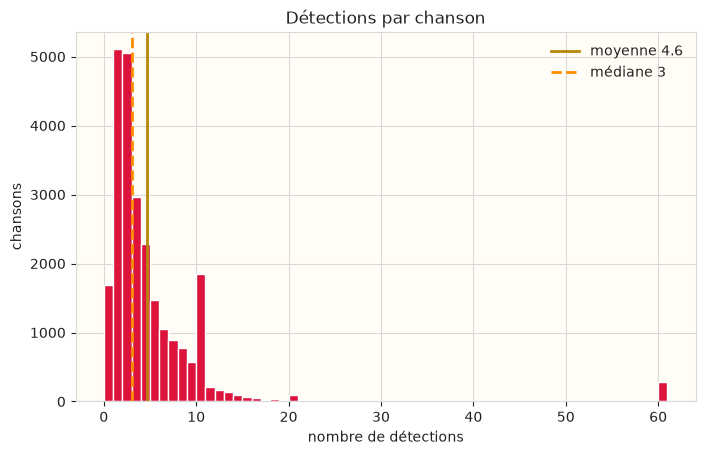

In [21]:
if ok_df is None or ok_df.empty:
    print('Histogramme indisponible sans résultats complets par chanson.')
else:
    fig, ax = nouvelle_figure('Détections par chanson', 'nombre de détections', 'chansons')
    ax.hist(ok_df['n_detections'], bins=range(0, int(ok_df['n_detections'].max()) + 2),
            color=CRAMOISI, edgecolor=FOND)
    ax.axvline(moyenne, color=OR, linewidth=2, label=f'moyenne {moyenne:.1f}')
    ax.axvline(mediane, color=ORANGE, linewidth=2, linestyle='--', label=f'médiane {mediane:.0f}')
    ax.legend(frameon=False, labelcolor=TEXTE)
    exporter(fig, 'cinema_detections_par_chanson')
    plt.show()


### 8.2 Distribution des principales figures


Figure exportée : images/cinema_detections_par_figure_2021_2024_all.png


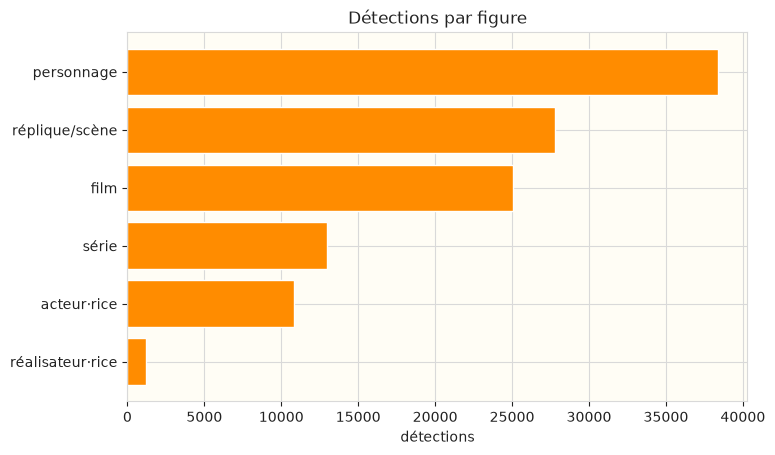

In [22]:
comptes_figures = detections_df['figure'].value_counts().sort_values()
fig, ax = nouvelle_figure('Détections par figure', 'détections')
ax.barh(comptes_figures.index, comptes_figures.values, color=ORANGE, edgecolor=FOND)
exporter(fig, 'cinema_detections_par_figure')
plt.show()


### 8.3 Évolution dans le temps

Nombre moyen de détections par chanson et par année (les années sans chanson
dans l'échantillon n'apparaissent pas).


Figure exportée : images/cinema_detections_par_annee_2021_2024_all.png


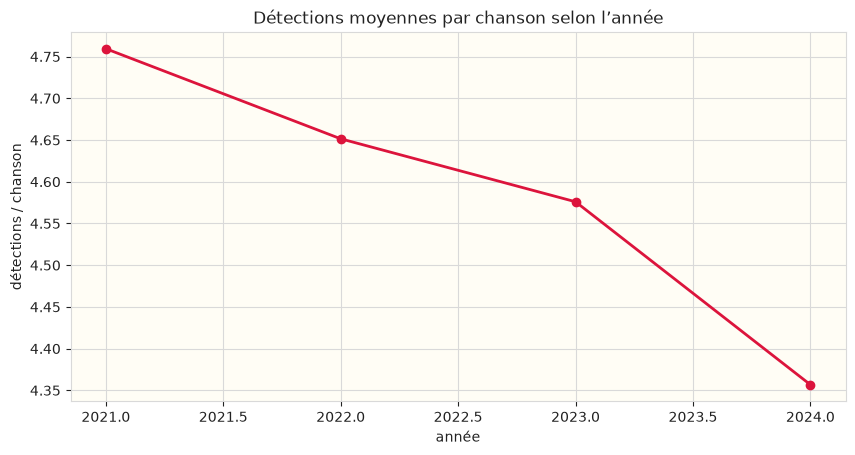

annee,2021,2022,2023,2024
détections_moyennes,4.8,4.7,4.6,4.4
chansons,7986.0,7658.0,7290.0,2105.0


In [23]:
if ok_df is None or ok_df.empty:
    print('Moyennes annuelles indisponibles sans résultats complets par chanson.')
else:
    par_annee = (ok_df.assign(annee=pd.to_numeric(ok_df['year'], errors='coerce'))
                 .dropna(subset=['annee']).astype({'annee': int})
                 .groupby('annee')['n_detections'].agg(['mean', 'count']))
    fig, ax = nouvelle_figure('Détections moyennes par chanson selon l’année',
                              'année', 'détections / chanson', figsize=(10, 4.8))
    ax.plot(par_annee.index, par_annee['mean'], color=CRAMOISI, marker='o', linewidth=2)
    exporter(fig, 'cinema_detections_par_annee')
    plt.show()
    with pd.option_context('display.max_columns', None):
        display(par_annee.rename(columns={'mean': 'détections_moyennes', 'count': 'chansons'}).round(1).T)


## 9. Nuages de mots par figure

Pour chaque figure, nuage des **20 termes les plus fréquents** parmi les extraits détectés.
La casse est normalisée pour le comptage (la graphie la plus fréquente est affichée) et la
taille des mots est proportionnelle à leur fréquence. Chaque nuage est exporté
individuellement dans `images/`.


In [24]:
from wordcloud import WordCloud

PALETTE_MOTS = [CRAMOISI, ORANGE, OR]
TOP_TERMES = 20
SLUGS = {'film': 'film', 'série': 'serie', 'personnage': 'personnage', 'acteur·rice': 'acteur',
         'réalisateur·rice': 'realisateur', 'réplique/scène': 'replique_scene'}

def couleur_mot(word, **kwargs):
    # Couleur stable par mot, indépendante de l'ordre de tirage
    return PALETTE_MOTS[sum(word.encode('utf-8')) % len(PALETTE_MOTS)]

def nuage_de_mots(figure):
    extraits = detections_df.loc[detections_df['figure'] == figure, 'extrait'].str.strip()
    if extraits.empty:
        print(f'Aucune détection pour la figure « {figure} ».')
        return
    normalises = extraits.str.casefold()
    graphies = extraits.groupby(normalises).agg(lambda s: s.value_counts().index[0])
    comptes = normalises.value_counts().head(TOP_TERMES)
    frequences = {graphies[terme]: int(n) for terme, n in comptes.items()}
    nuage = WordCloud(width=1000, height=500, background_color=FOND_AXES,
                      color_func=couleur_mot, max_words=TOP_TERMES, prefer_horizontal=0.9,
                      random_state=SEED).generate_from_frequencies(frequences)
    fig, ax = plt.subplots(figsize=(10, 5), facecolor=FOND)
    ax.imshow(nuage, interpolation='bilinear')
    ax.axis('off')
    ax.set_title(f'{figure} — top {len(frequences)} termes sur {normalises.nunique()} distincts '
                 f'({len(extraits)} détections)', color=TEXTE)
    exporter(fig, f'cinema_nuage_{SLUGS[figure]}')
    plt.show()
    display(pd.Series(frequences, name='occurrences').to_frame().T)

print('Prêt. Figures :', list(SLUGS))


Prêt. Figures : ['film', 'série', 'personnage', 'acteur·rice', 'réalisateur·rice', 'réplique/scène']


### 9.1 Film


Figure exportée : images/cinema_nuage_film_2021_2024_all.png


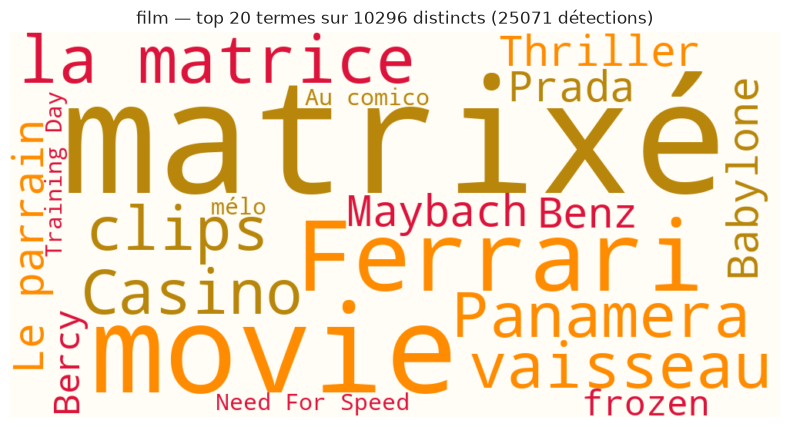

,matrixé,movie,Ferrari,la matrice,vaisseau,Panamera,Casino,clips,Maybach,Thriller,Le parrain,Prada,Babylone,Benz,frozen,Bercy,Need For Speed,Au comico,Training Day,mélo
occurrences,285,154,92,87,79,78,76,75,75,72,71,71,70,68,67,67,67,66,66,66


In [25]:
nuage_de_mots('film')


### 9.2 Série


Figure exportée : images/cinema_nuage_serie_2021_2024_all.png


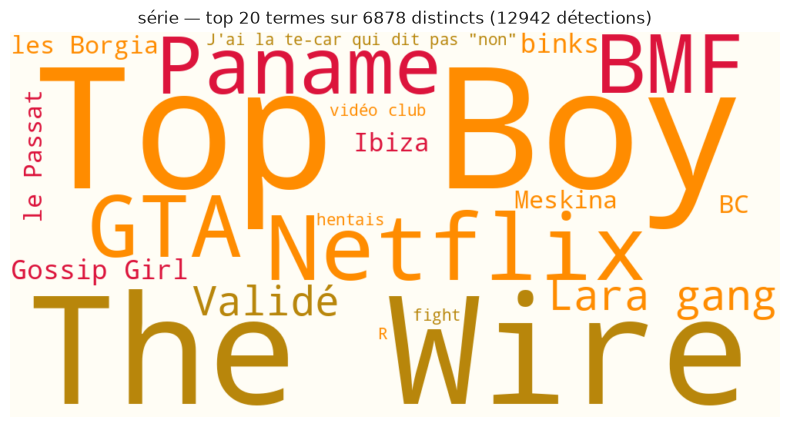

,Top Boy,The Wire,Netflix,GTA,BMF,Paname,Lara gang,Validé,Gossip Girl,binks,Ibiza,BC,les Borgia,le Passat,Meskina,"J'ai la te-car qui dit pas ""non""",vidéo club,R,fight,hentais
occurrences,152,119,97,87,79,73,71,66,66,64,62,60,60,60,60,60,60,60,60,60


In [26]:
nuage_de_mots('série')


### 9.3 Personnage


Figure exportée : images/cinema_nuage_personnage_2021_2024_all.png


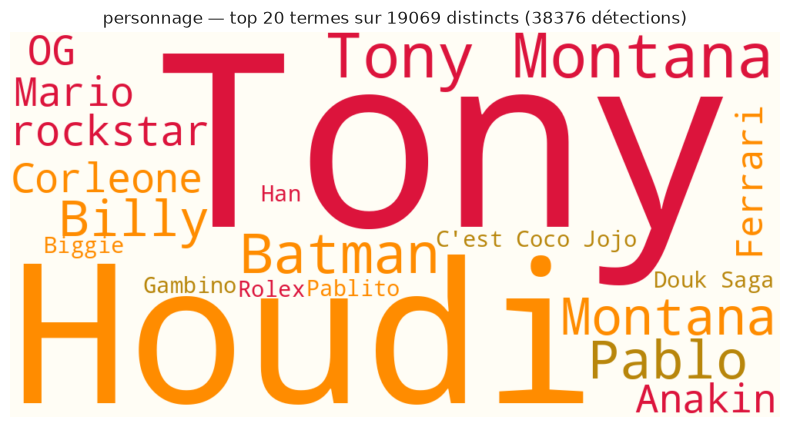

,Tony,Houdi,Tony Montana,Batman,Pablo,Montana,Billy,rockstar,Corleone,OG,Mario,Anakin,Ferrari,C'est Coco Jojo,Gambino,Rolex,Biggie,Pablito,Han,Douk Saga
occurrences,154,145,142,111,103,97,91,88,82,82,82,78,70,70,69,67,65,65,63,63


In [27]:
nuage_de_mots('personnage')


### 9.4 Acteur·rice


Figure exportée : images/cinema_nuage_acteur_2021_2024_all.png


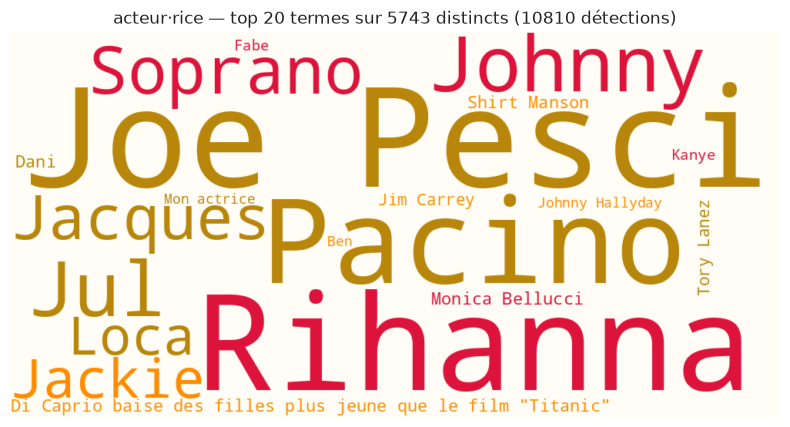

,Joe Pesci,Rihanna,Pacino,Johnny,Jul,Soprano,Jacques,Jackie,Loca,"Di Caprio baise des filles plus jeune que le film ""Titanic""",Shirt Manson,Monica Bellucci,Dani,Tory Lanez,Jim Carrey,Kanye,Fabe,Ben,Johnny Hallyday,Mon actrice
occurrences,101,93,72,67,66,65,65,61,60,59,58,58,58,54,53,43,43,40,38,36


In [28]:
nuage_de_mots('acteur·rice')


### 9.5 Réalisateur·rice


Figure exportée : images/cinema_nuage_realisateur_2021_2024_all.png


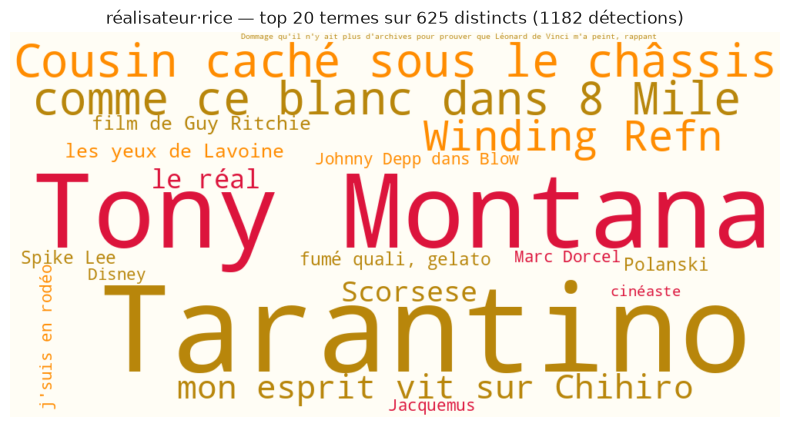

,Tarantino,Tony Montana,Cousin caché sous le châssis,comme ce blanc dans 8 Mile,Winding Refn,mon esprit vit sur Chihiro,Scorsese,le réal,les yeux de Lavoine,film de Guy Ritchie,Spike Lee,Polanski,"fumé quali, gelato",j'suis en rodéo,Marc Dorcel,Disney,Johnny Depp dans Blow,Jacquemus,cinéaste,"Dommage qu'il n'y ait plus d'archives pour prouver que Léonard de Vinci m'a peint, rappant"
occurrences,80,57,55,55,46,28,20,17,8,8,7,7,7,6,6,6,6,6,5,5


In [29]:
nuage_de_mots('réalisateur·rice')


### 9.6 Réplique/scène


Figure exportée : images/cinema_nuage_replique_scene_2021_2024_all.png


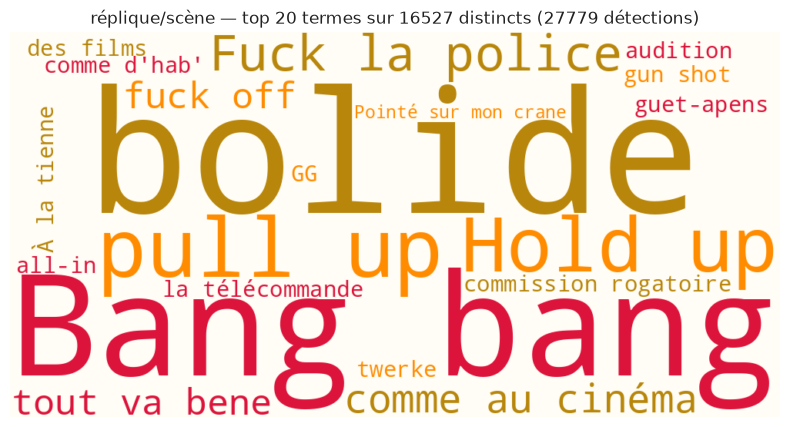

,bolide,Bang bang,pull up,Hold up,Fuck la police,comme au cinéma,tout va bene,fuck off,commission rogatoire,guet-apens,twerke,gun shot,des films,all-in,audition,GG,la télécommande,comme d'hab',À la tienne,Pointé sur mon crane
occurrences,92,78,72,66,65,64,63,63,61,61,61,61,61,61,61,60,60,60,60,60


In [30]:
nuage_de_mots('réplique/scène')
